<a href="https://colab.research.google.com/github/Rajaneesh-Netha/Pneumonia-Detection/blob/main/ML_Case_study_Pneumonia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 4.6 MB/s eta 0:00:00
device: cpu


100%|██████████| 4.17M/4.17M [00:10<00:00, 387kB/s]


train: 4708 | val: 524 | test: 624
PneumoniaCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
total params: 105281
epoch 1/10 | loss: 0.4296 | val acc: 89.89%
epoch 2/10 | loss: 0.1673 | val acc: 95.61%
epoch 3/10 | loss: 0.1370 | val acc: 96.18%
epoch 4/10 | loss: 0.1163 | val acc: 95.80%
epoch 5/10 | loss: 0.1151 | val acc: 96.18%
epoch 6/10 | loss: 0.1057 | val acc: 95.61%
epoch 7/10 | loss: 0.0998 | val acc

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

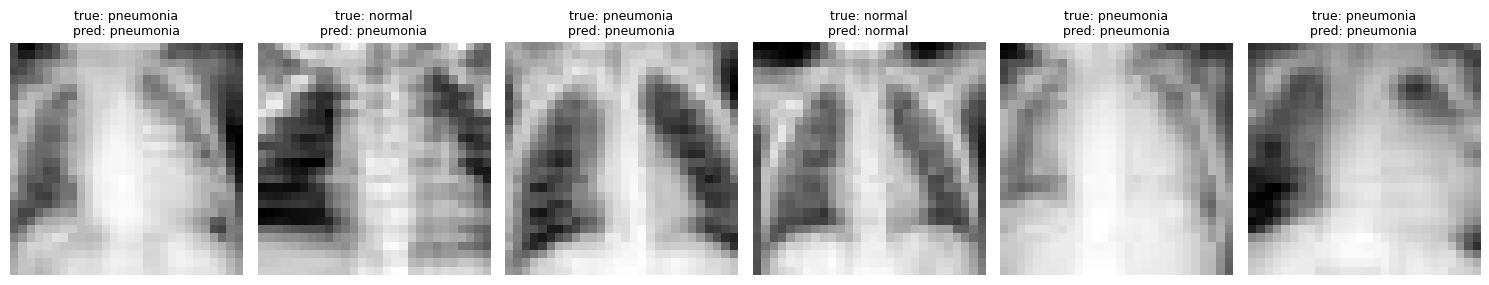

CNN accuracy (sklearn): 83.81%  |  Section 5 accuracy: 83.81%

CNN classification report:
              precision    recall  f1-score   support

      Normal     0.9716    0.5855    0.7307       234
   Pneumonia     0.7992    0.9897    0.8843       390

    accuracy                         0.8381       624
   macro avg     0.8854    0.7876    0.8075       624
weighted avg     0.8638    0.8381    0.8267       624

train: X (4708, 784) | Normal(0): 1214 | Pneumonia(1): 3494
val  : X (524, 784) | Normal(0): 135 | Pneumonia(1): 389
test : X (624, 784) | Normal(0): 234 | Pneumonia(1): 390

Feature range after normalization: [-1.00, 1.00]
90% variance -> 31 components
95% variance -> 71 components
99% variance -> 243 components


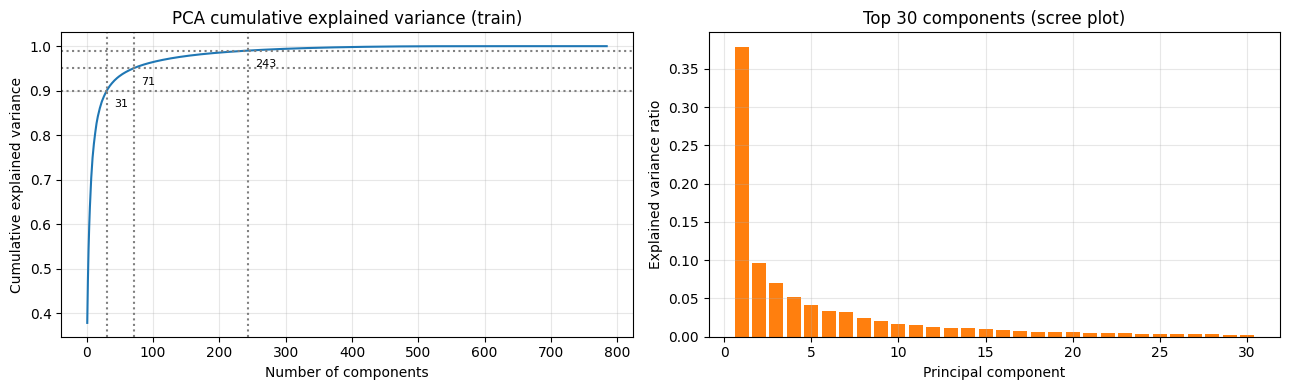

Top 10 configurations by validation accuracy:
 n_components   C  gamma_mult class_weight  val_acc
           31 100         0.5         None 0.973282
           71  10         1.0         None 0.973282
          243  10         1.0     balanced 0.969466
           71  10         1.0     balanced 0.969466
           71  10         0.5         None 0.969466
          243 100         0.5     balanced 0.969466
          243 100         0.5         None 0.969466
           71 100         0.5     balanced 0.967557
           71  10         0.5     balanced 0.967557
           31  10         0.5         None 0.967557

Selected -> components: 31 | C: 100.0 | gamma: 0.5 x scale | class_weight: None
PCA: 784 -> 31 features | variance retained: 90.16%

PCA + SVM classification report (test):
              precision    recall  f1-score   support

      Normal     0.9441    0.6496    0.7696       234
   Pneumonia     0.8229    0.9769    0.8933       390

    accuracy                         0.8542 

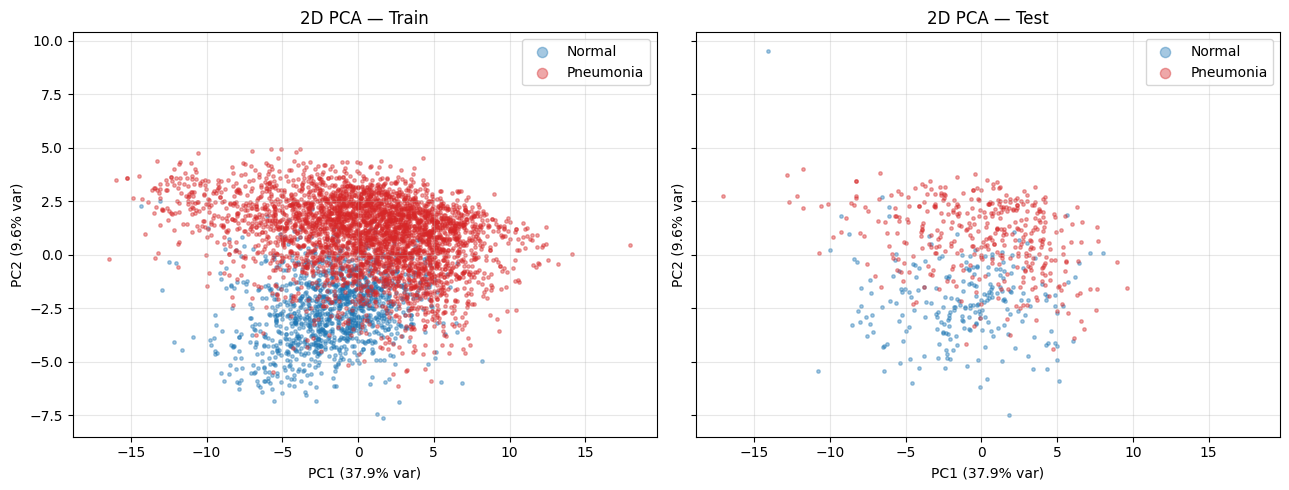

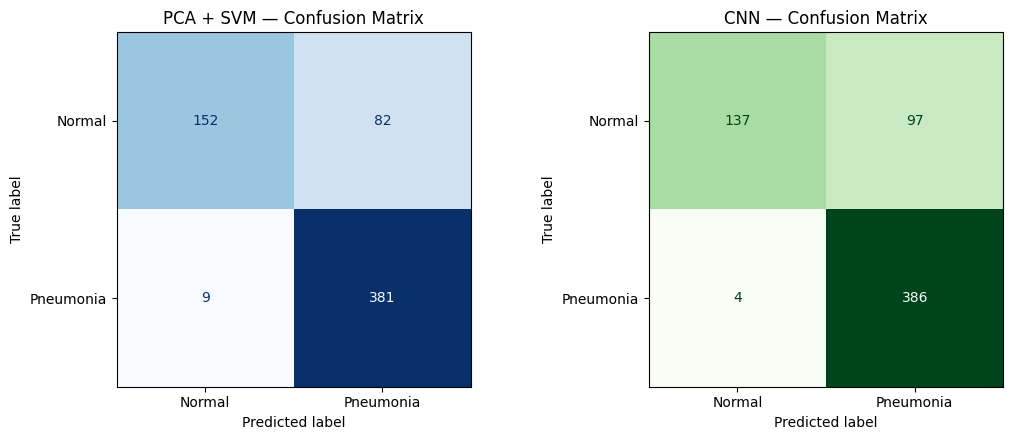

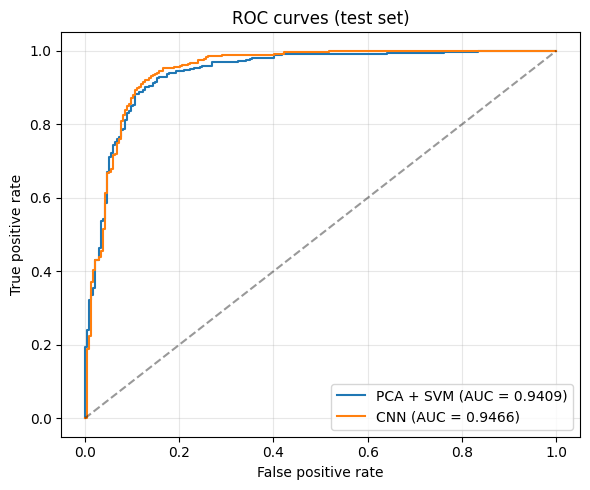


TEST SET COMPARISON (positive class = Pneumonia)
Model         Accuracy   Precision    Recall       F1   ROC-AUC
PCA + SVM       0.8542      0.8229    0.9769   0.8933    0.9409
CNN             0.8381      0.7992    0.9897   0.8843    0.9466

PCA + SVM settings: 31 components (90.2% variance), RBF kernel, C=100.0, gamma=0.01043, class_weight=None
saved: model_comparison.csv


In [ ]:
# SECTION 1 — SETUP
# install the medmnist package — gives us access to PneumoniaMNIST and other medical datasets
!pip install medmnist -q

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
from medmnist import PneumoniaMNIST

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

# SECTION 2 — DATA
# preprocessing: convert images to tensors, then normalize pixel values
# to roughly [-1, 1] — helps the model train faster and more stably
data_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

# load the three splits: train (to learn from), val (to check progress),
# test (final, unseen accuracy check) — download=True grabs the data automatically
train_dataset = PneumoniaMNIST(split='train', transform=data_transform, download=True)
val_dataset = PneumoniaMNIST(split='val', transform=data_transform, download=True)
test_dataset = PneumoniaMNIST(split='test', transform=data_transform, download=True)

# sanity check — confirm how many images are in each split
print(f'train: {len(train_dataset)} | val: {len(val_dataset)} | test: {len(test_dataset)}')

# wrap each dataset in a DataLoader — batches of 64 images at a time,
# shuffled for training so the model doesn't memorize order
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# SECTION 3 — CNN MODEL
# defining the CNN architecture
class PneumoniaCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # feature extractor: scans the image for patterns (edges, textures, shapes)
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),  # 1 grayscale channel in, 16 filters out
            nn.ReLU(),                                    # adds non-linearity so the model can learn complex patterns
            nn.MaxPool2d(2),  # shrinks image size 28 -> 14, keeps the strongest features

            nn.Conv2d(16, 32, kernel_size=3, padding=1),  # deepens the network — 16 filters in, 32 out
            nn.ReLU(),
            nn.MaxPool2d(2),  # shrinks again 14 -> 7
        )

        # classifier: takes the extracted features and decides normal vs pneumonia
        self.classifier = nn.Sequential(
            nn.Flatten(),                    # flattens the 3D feature map into a 1D list
            nn.Linear(32 * 7 * 7, 64),        # fully connected layer, compresses down to 64 values
            nn.ReLU(),
            nn.Dropout(0.3),                  # randomly turns off 30% of neurons during training — prevents overfitting
            nn.Linear(64, 1)                  # final output: one number (higher = more likely pneumonia)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = PneumoniaCNN().to(device)
print(model)

print('total params:', sum(p.numel() for p in model.parameters()))

# SECTION 4 — CNN TRAINING

import time

# loss function: measures how wrong the model's predictions are (for binary yes/no problems)
criterion = nn.BCEWithLogitsLoss()

# optimizer: updates the model's weights to reduce that loss over time
optimizer = optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 10
start_time = time.time()

for epoch in range(EPOCHS):
    #training phase
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device).float()

        optimizer.zero_grad()
        outputs = model(images).squeeze(1)
        loss = criterion(outputs, labels.squeeze(1))
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    #validation phase
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device).float().squeeze(1)
            outputs = torch.sigmoid(model(images).squeeze(1))  # sigmoid converts raw output to a 0-1 probability
            preds = (outputs > 0.5).float()                     # above 0.5 = predict pneumonia
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    print(f'epoch {epoch+1}/{EPOCHS} | loss: {running_loss/len(train_loader):.4f} | val acc: {100*correct/total:.2f}%')

elapsed = time.time() - start_time

# total time spent training — good for your "took X minutes" line in the video
print(f'\ntraining time: {elapsed/60:.1f}')

# SECTION 5 — CNN TEST ACCURACY (UNCHANGED)
# switch to evaluation mode
model.eval()

correct, total = 0, 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device).float().squeeze(1)

        outputs = torch.sigmoid(model(images).squeeze(1))  # convert raw output to a 0-1 probability
        preds = (outputs > 0.5).float()                     # above 0.5 = model predicts pneumonia

        correct += (preds == labels).sum().item()           # count how many predictions matched the true label
        total += labels.size(0)

# this is the real, unbiased accuracy number
test_acc = 100 * correct / total
print(f'FINAL TEST ACCURACY: {test_acc:.2f}%')

# SECTION 6 — CNN MODEL SAVING
# save just the model's learned weights to a file
torch.save(model.state_dict(), 'pneumonia_model.pth')
print('saved: pneumonia_model.pth')

from google.colab import files
files.download('pneumonia_model.pth')

# SECTION 7 — CNN SAMPLE PREDICTIONS

import matplotlib.pyplot as plt

images, labels = next(iter(test_loader))
images_gpu = images.to(device)

with torch.no_grad():
    preds = torch.sigmoid(model(images_gpu).squeeze(1)) > 0.5  # True = predicted pneumonia

fig, axes = plt.subplots(1, 6, figsize=(15, 3))

for i, ax in enumerate(axes):
    img = images[i][0].numpy()
    true_label = 'pneumonia' if labels[i].item() == 1 else 'normal'
    pred_label = 'pneumonia' if preds[i].item() == 1 else 'normal'

    ax.imshow(img, cmap='gray')
    ax.set_title(f'true: {true_label}\npred: {pred_label}', fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.savefig('sample_predictions.png', dpi=150)
plt.show()

# SECTION 8 — CNN FULL METRICS (read-only evaluation of the trained model)

import pandas as pd
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, classification_report)

CLASS_NAMES = ['Normal', 'Pneumonia']   # label 0 = Normal, label 1 = Pneumonia

def compute_metrics(y_true, y_pred, y_score):
    """Accuracy / Precision / Recall / F1 (positive class = Pneumonia) + ROC-AUC."""
    return {
        'Accuracy':  accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall':    recall_score(y_true, y_pred, zero_division=0),
        'F1':        f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC':   roc_auc_score(y_true, y_score),
    }

model.eval()
cnn_probs, cnn_true = [], []
with torch.no_grad():
    for images, labels in test_loader:
        probs = torch.sigmoid(model(images.to(device)).squeeze(1))
        cnn_probs.append(probs.cpu().numpy())
        cnn_true.append(labels.numpy().reshape(-1))

cnn_probs = np.concatenate(cnn_probs)
y_test_cnn = np.concatenate(cnn_true).astype(int)
cnn_preds = (cnn_probs > 0.5).astype(int)

cnn_metrics = compute_metrics(y_test_cnn, cnn_preds, cnn_probs)
cnn_cm = confusion_matrix(y_test_cnn, cnn_preds)

print(f'CNN accuracy (sklearn): {100*cnn_metrics["Accuracy"]:.2f}%  |  Section 5 accuracy: {test_acc:.2f}%')
print('\nCNN classification report:')
print(classification_report(y_test_cnn, cnn_preds, target_names=CLASS_NAMES, digits=4))


# SECTION 9 — PCA + SVM: DATA PREPARATION (same splits, same normalization)
def dataset_to_numpy(ds):
    X = np.empty((len(ds), 28 * 28), dtype=np.float32)
    y = np.empty(len(ds), dtype=np.int64)
    for i in range(len(ds)):
        img, lbl = ds[i]                       # img: normalized tensor (1, 28, 28)
        X[i] = img.numpy().reshape(-1)         # flatten to 784 features
        y[i] = int(np.asarray(lbl).item())
    return X, y

X_train, y_train = dataset_to_numpy(train_dataset)
X_val,   y_val   = dataset_to_numpy(val_dataset)
X_test,  y_test  = dataset_to_numpy(test_dataset)

#Normal = 0, Pneumonia = 1
for name, y in [('train', y_train), ('val', y_val), ('test', y_test)]:
    assert set(np.unique(y)) <= {0, 1}, f'{name} labels are not binary!'
    print(f'{name:5s}: X {X_train.shape[1] and ""}{X_val.shape if name=="val" else (X_train.shape if name=="train" else X_test.shape)}'
          f' | Normal(0): {(y==0).sum()} | Pneumonia(1): {(y==1).sum()}')

assert np.array_equal(y_test, y_test_cnn), 'Test label mismatch between CNN and ML pipeline!'
print(f'\nFeature range after normalization: [{X_train.min():.2f}, {X_train.max():.2f}]')


# SECTION 10 — PCA: FIT ON TRAIN ONLY, EXPLAINED VARIANCE


from sklearn.decomposition import PCA
from sklearn.svm import SVC


pca_full = PCA(svd_solver='full', random_state=42).fit(X_train)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)


VARIANCE_TARGETS = [0.90, 0.95, 0.99]
candidate_k = [int(np.searchsorted(cum_var, t) + 1) for t in VARIANCE_TARGETS]
for t, k in zip(VARIANCE_TARGETS, candidate_k):
    print(f'{int(t*100)}% variance -> {k} components')


fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(np.arange(1, len(cum_var) + 1), cum_var, color='tab:blue')
for t, k in zip(VARIANCE_TARGETS, candidate_k):
    axes[0].axhline(t, ls=':', color='gray')
    axes[0].axvline(k, ls=':', color='gray')
    axes[0].annotate(f'{k}', (k, t), textcoords='offset points', xytext=(5, -12), fontsize=8)
axes[0].set_xlabel('Number of components')
axes[0].set_ylabel('Cumulative explained variance')
axes[0].set_title('PCA cumulative explained variance (train)')
axes[0].grid(alpha=0.3)

axes[1].bar(np.arange(1, 31), pca_full.explained_variance_ratio_[:30], color='tab:orange')
axes[1].set_xlabel('Principal component')
axes[1].set_ylabel('Explained variance ratio')
axes[1].set_title('Top 30 components (scree plot)')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig('pca_explained_variance.png', dpi=150)
plt.show()


# SECTION 11 — SVM (RBF) MODEL SELECTION ON THE VALIDATION SET
C_GRID      = [1, 10, 100]
GAMMA_MULTS = [0.5, 1.0, 2.0]
CLASS_WTS   = [None, 'balanced']

results = []
for k in candidate_k:
    pca_k = PCA(n_components=k, svd_solver='full', random_state=42).fit(X_train)
    Ztr, Zva = pca_k.transform(X_train), pca_k.transform(X_val)
    gamma_scale = 1.0 / (k * Ztr.var())
    for C in C_GRID:
        for gm in GAMMA_MULTS:
            for cw in CLASS_WTS:
                svm = SVC(kernel='rbf', C=C, gamma=gamma_scale * gm, class_weight=cw)
                svm.fit(Ztr, y_train)
                val_acc = accuracy_score(y_val, svm.predict(Zva))
                results.append({'n_components': k, 'C': C, 'gamma_mult': gm,
                                'class_weight': cw, 'val_acc': val_acc})

results_df = pd.DataFrame(results).sort_values('val_acc', ascending=False).reset_index(drop=True)
print('Top 10 configurations by validation accuracy:')
print(results_df.head(10).to_string(index=False))

best = results_df.iloc[0]
best_k  = int(best['n_components'])
best_C  = float(best['C'])
best_gm = float(best['gamma_mult'])
best_cw = None if pd.isna(best['class_weight']) else best['class_weight']
print(f'\nSelected -> components: {best_k} | C: {best_C} | gamma: {best_gm} x scale | class_weight: {best_cw}')

# SECTION 12 — FINAL PCA + SVM (fit on TRAIN only, evaluate on TEST)
pca = PCA(n_components=best_k, svd_solver='full', random_state=42)
Z_train = pca.fit_transform(X_train)
Z_val   = pca.transform(X_val)
Z_test  = pca.transform(X_test)
print(f'PCA: 784 -> {best_k} features | variance retained: {100*pca.explained_variance_ratio_.sum():.2f}%')

gamma_final = best_gm / (best_k * Z_train.var())
svm = SVC(kernel='rbf', C=best_C, gamma=gamma_final, class_weight=best_cw)
svm.fit(Z_train, y_train)

svm_preds  = svm.predict(Z_test)
svm_scores = svm.decision_function(Z_test)

svm_metrics = compute_metrics(y_test, svm_preds, svm_scores)
svm_cm = confusion_matrix(y_test, svm_preds)

print('\nPCA + SVM classification report (test):')
print(classification_report(y_test, svm_preds, target_names=CLASS_NAMES, digits=4))

# SECTION 13 — 2D PCA VISUALIZATION
Z2_train = pca_full.transform(X_train)[:, :2]
Z2_test  = pca_full.transform(X_test)[:, :2]
ev2 = pca_full.explained_variance_ratio_[:2]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, Z2, y, title in [(axes[0], Z2_train, y_train, 'Train'), (axes[1], Z2_test, y_test, 'Test')]:
    for cls, color in [(0, 'tab:blue'), (1, 'tab:red')]:
        m = y == cls
        ax.scatter(Z2[m, 0], Z2[m, 1], s=6, alpha=0.4, c=color, label=CLASS_NAMES[cls])
    ax.set_title(f'2D PCA — {title}')
    ax.set_xlabel(f'PC1 ({100*ev2[0]:.1f}% var)')
    ax.set_ylabel(f'PC2 ({100*ev2[1]:.1f}% var)')
    ax.legend(markerscale=3)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('pca_2d.png', dpi=150)
plt.show()

# SECTION 14 — CONFUSION MATRICES

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(svm_cm, display_labels=CLASS_NAMES).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('PCA + SVM — Confusion Matrix')
ConfusionMatrixDisplay(cnn_cm, display_labels=CLASS_NAMES).plot(ax=axes[1], cmap='Greens', colorbar=False)
axes[1].set_title('CNN — Confusion Matrix')
plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150)
plt.show()

# SECTION 15 — ROC CURVES

fpr_s, tpr_s, _ = roc_curve(y_test, svm_scores)
fpr_c, tpr_c, _ = roc_curve(y_test, cnn_probs)

plt.figure(figsize=(6, 5))
plt.plot(fpr_s, tpr_s, label=f'PCA + SVM (AUC = {svm_metrics["ROC-AUC"]:.4f})')
plt.plot(fpr_c, tpr_c, label=f'CNN (AUC = {cnn_metrics["ROC-AUC"]:.4f})')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.4)
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curves (test set)')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curves.png', dpi=150)
plt.show()


# SECTION 16 — FINAL COMPARISON TABLE
comparison = pd.DataFrame(
    [svm_metrics, cnn_metrics],
    index=['PCA + SVM', 'CNN']
)[['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']]

print('\n' + '=' * 68)
print('TEST SET COMPARISON (positive class = Pneumonia)')
print('=' * 68)
print(f'{"Model":<12}{"Accuracy":>10}{"Precision":>12}{"Recall":>10}{"F1":>9}{"ROC-AUC":>10}')
for name, row in comparison.iterrows():
    print(f'{name:<12}{row["Accuracy"]:>10.4f}{row["Precision"]:>12.4f}{row["Recall"]:>10.4f}'
          f'{row["F1"]:>9.4f}{row["ROC-AUC"]:>10.4f}')
print('=' * 68)
print(f'\nPCA + SVM settings: {best_k} components '
      f'({100*pca.explained_variance_ratio_.sum():.1f}% variance), RBF kernel, '
      f'C={best_C}, gamma={gamma_final:.5f}, class_weight={best_cw}')

comparison.round(4).to_csv('model_comparison.csv')
print('saved: model_comparison.csv')

In [ ]:

# SECTION 17 — UPLOAD YOUR OWN X-RAY IMAGES AND PREDICT (CNN + PCA/SVM)

import io, re, math
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from google.colab import files

ALLOWED_EXT = ('.png', '.jpg', '.jpeg', '.jfif', '.bmp', '.gif', '.tif', '.tiff', '.webp', '.pgm', '.ppm')

def load_as_gray(raw_bytes):
    """Open any supported image and return an 8-bit grayscale PIL image."""
    img = Image.open(io.BytesIO(raw_bytes))
    img.load()
    try:
        img.seek(0)                                    # animated gif/tiff -> first frame only
    except Exception:
        pass
    img = ImageOps.exif_transpose(img)                 # respect phone/camera rotation
    if img.mode in ('I;16', 'I;16B', 'I;16L', 'I', 'F'):
        arr = np.asarray(img).astype(np.float64)       # 16-bit / float images: rescale to 0-255
        lo, hi = arr.min(), arr.max()
        arr = (arr - lo) / (hi - lo) * 255.0 if hi > lo else np.zeros_like(arr)
        return Image.fromarray(arr.astype(np.uint8), mode='L')
    if img.mode in ('RGBA', 'LA', 'P'):
        img = img.convert('RGBA')
        bg = Image.new('RGBA', img.size, (0, 0, 0, 255))
        img = Image.alpha_composite(bg, img)           # flatten transparency onto black
    return img.convert('L')

def to_model_tensor(gray_img):
    """Same pipeline as training: center-crop square -> 28x28 -> ToTensor + Normalize(0.5, 0.5)."""
    w, h = gray_img.size
    s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    small = gray_img.crop((left, top, left + s, top + s)).resize((28, 28), Image.LANCZOS)
    return small, data_transform(small)                # tensor shape (1, 28, 28)

def label_from_filename(name):
    """Optional: guess the true label from the filename (for an accuracy check)."""
    n = name.lower()
    if 'pneumonia' in n or 'bacteria' in n or 'virus' in n:
        return 1
    if re.search(r'(^|[^a-z])normal', n):
        return 0
    return None

def predict_uploaded_images():

    needed = ['model', 'data_transform', 'device', 'CLASS_NAMES']
    missing = [n for n in needed if n not in globals()]
    if missing:
        print('Missing:', ', '.join(missing))
        print('Please run Sections 1-16 of this notebook first (Runtime > Run all), then run this cell again.')
        return
    have_svm = ('pca' in globals()) and ('svm' in globals())

    print('Choose one or more X-ray images (png / jpg / jpeg / bmp / gif / tif / webp)...')
    uploaded = files.upload()
    if not uploaded:
        print('No files were uploaded. Run the cell again and select at least one image.')
        return

    model.eval()
    records, shown = [], []

    for fname, raw in uploaded.items():
        if not fname.lower().endswith(ALLOWED_EXT):
            print(f'skipped (unsupported format): {fname}')
            continue
        try:
            gray = load_as_gray(raw)
            small, tensor = to_model_tensor(gray)

            with torch.no_grad():
                p = torch.sigmoid(model(tensor.unsqueeze(0).to(device)).squeeze(1)).item()
            cnn_pred = int(p > 0.5)

            rec = {'File': fname,
                   'CNN': CLASS_NAMES[cnn_pred],
                   'CNN P(pneumonia)': round(p, 4)}

            if have_svm:
                z = pca.transform(tensor.numpy().reshape(1, -1).astype(np.float64))
                svm_pred = int(svm.predict(z)[0])
                rec['PCA+SVM'] = CLASS_NAMES[svm_pred]

            true = label_from_filename(fname)
            if true is not None:
                rec['True (from filename)'] = CLASS_NAMES[true]
                rec['CNN correct'] = (cnn_pred == true)
                if have_svm:
                    rec['SVM correct'] = (svm_pred == true)

            records.append(rec)
            shown.append((gray, fname, cnn_pred, p, true))
        except Exception as e:
            print(f'skipped (could not read image): {fname} -> {type(e).__name__}: {e}')

    if not records:
        print('No valid images were processed. Please upload png / jpg / jpeg files.')
        return

    sub = shown[:24]
    cols = min(4, len(sub))
    rows_n = math.ceil(len(sub) / cols)
    fig, axes = plt.subplots(rows_n, cols, figsize=(3.6 * cols, 3.9 * rows_n))
    axes = np.atleast_1d(axes).ravel()
    for ax, (gray, fname, pred, p, true) in zip(axes, sub):
        conf = p if pred == 1 else 1 - p
        color = 'black' if true is None else ('green' if pred == true else 'red')
        ax.imshow(gray, cmap='gray')
        ax.set_title(f'CNN: {CLASS_NAMES[pred]} ({100*conf:.1f}%)\n{fname[:30]}', fontsize=9, color=color)
        ax.axis('off')
    for ax in axes[len(sub):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()
    if len(shown) > 24:
        print(f'(showing the first 24 of {len(shown)} images; all results are in the table below)')

    # results table
    df = pd.DataFrame(records)
    print(df.to_string(index=False))


    if 'CNN correct' in df.columns:
        known = df.dropna(subset=['CNN correct'])
        print(f'\nCNN accuracy on {len(known)} labelled image(s): '
              f'{100 * known["CNN correct"].astype(bool).mean():.2f}%')
        if have_svm and 'SVM correct' in known.columns:
            print(f'PCA+SVM accuracy on {len(known)} labelled image(s): '
                  f'{100 * known["SVM correct"].astype(bool).mean():.2f}%')

predict_uploaded_images()